<a href="https://colab.research.google.com/github/akshaybhatt97/365-DAYS-AI-ML-WITH-AKSHAY/blob/main/day_088_weight_initialization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 88/365 — Weight Initialization: Xavier vs He

Yesterday we learned about **Vanishing and Exploding Gradients**.

Today we look at one practical way to reduce those problems:

**better weight initialization**

Neural-network weights start randomly, but the scale of those random values matters.


In [1]:
import numpy as np
import matplotlib.pyplot as plt


## 1. Why not initialize every weight to zero?

If all neurons start with the same weights, they receive the same gradients and keep learning the same features.

This is called a **symmetry problem**.

So weights need random initialization.


## 2. Why random scale matters

If weights are too small:

- activations may shrink
- gradients may vanish

If weights are too large:

- activations may explode
- gradients may explode

Good initialization tries to keep signal variance reasonably stable across layers.


## 3. Xavier / Glorot initialization

Commonly associated with:

- Tanh
- Sigmoid

A common variance rule is:

`Var(w) ≈ 2 / (fan_in + fan_out)`

where:

- `fan_in` = number of inputs
- `fan_out` = number of outputs


## 4. He / Kaiming initialization

Designed for ReLU-style activations.

Typical variance:

`Var(w) ≈ 2 / fan_in`

ReLU sets negative activations to zero, so He initialization uses a larger starting variance to preserve signal strength better.


In [2]:
fan_in = 100

xavier_std = np.sqrt(1 / fan_in)
he_std = np.sqrt(2 / fan_in)

print("Approx Xavier std:", round(xavier_std,4))
print("He std:", round(he_std,4))


Approx Xavier std: 0.1
He std: 0.1414


## 5. Simulate signal variance through deep ReLU layers


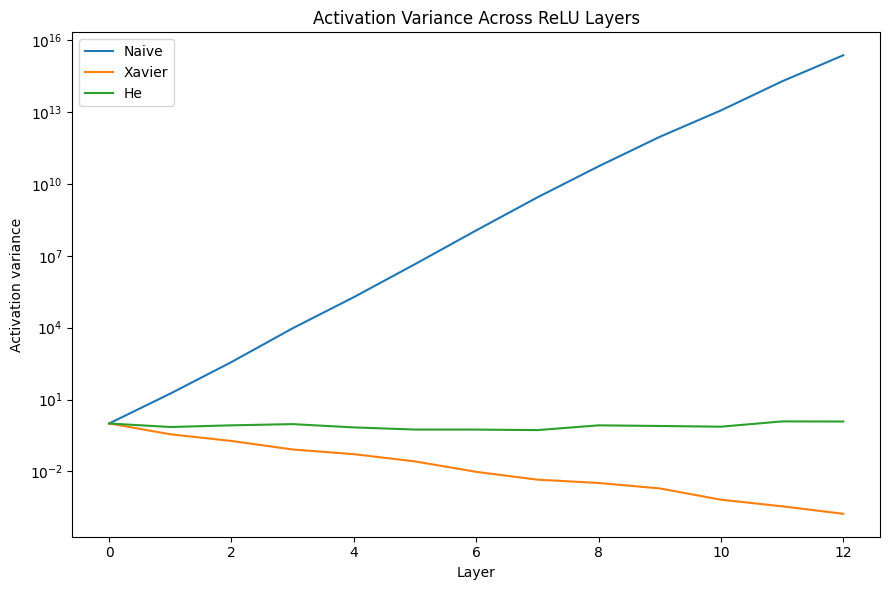

In [3]:
rng=np.random.default_rng(42)

samples=500
width=50
layers=12

def simulate(method):
    x=rng.normal(0,1,size=(samples,width))
    variances=[x.var()]

    for _ in range(layers):
        if method=="naive":
            std=1.0
        elif method=="xavier":
            std=np.sqrt(1/width)
        else:
            std=np.sqrt(2/width)

        W=rng.normal(0,std,size=(width,width))
        x=np.maximum(0,x @ W)
        variances.append(x.var())

    return variances

naive=simulate("naive")
xavier=simulate("xavier")
he=simulate("he")

plt.figure(figsize=(9,6))
plt.plot(naive,label="Naive")
plt.plot(xavier,label="Xavier")
plt.plot(he,label="He")
plt.yscale("log")
plt.xlabel("Layer")
plt.ylabel("Activation variance")
plt.title("Activation Variance Across ReLU Layers")
plt.legend()
plt.tight_layout()
plt.show()


## 6. Simple rule of thumb

### ReLU / Leaky ReLU
Start with **He initialization**

### Tanh / Sigmoid
Start with **Xavier / Glorot initialization**

Modern frameworks provide both directly.


## Simple takeaway

Good initialization does not teach the network the answer.

It simply gives training a healthier starting point.

> **Too small can make the signal vanish. Too large can make it explode. Xavier and He try to keep the signal in a useful range.**


## References

- Glorot & Bengio (2010):
  https://proceedings.mlr.press/v9/glorot10a.html

- He et al. (2015):
  https://arxiv.org/abs/1502.01852

- PyTorch initialization:
  https://pytorch.org/docs/stable/nn.init.html
